In [1]:
import os
import cv2
import math
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from PIL import Image
from torchvision import transforms, models

from sahi import AutoDetectionModel
from sahi.predict import get_sliced_prediction

In [2]:
# ==========================================
# CONFIGURATION
# ==========================================

IMG1_PATH = '../data/raw/test_fullsized_images/IAS_27288_Rotation1_300dpi.png'
IMG2_PATH = '../data/raw/test_fullsized_images/IAS_27288_Rotation2_300dpi.png'

YOLO_MODEL_PATH = '../runs/obb/train3/weights/best.pt'
CLS_MODEL_PATH = '../models/greek_classifier_resnet18_20260214_212940.pth'

TRAIN_DIR = '../data/processed/greek_letters_classification/train'

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

CLASS_NAMES = sorted([
    d for d in os.listdir(TRAIN_DIR)
    if os.path.isdir(os.path.join(TRAIN_DIR, d))
])

print(f"Loaded {len(CLASS_NAMES)} classes.")

Loaded 27 classes.


In [3]:
# Detection

detection_model = AutoDetectionModel.from_pretrained(
    model_type='yolov8',
    model_path=YOLO_MODEL_PATH,
    confidence_threshold=0.25,
    device=DEVICE,
)

# Classification

classifier = models.resnet18(weights=None)

classifier.fc = nn.Linear(
    classifier.fc.in_features,
    len(CLASS_NAMES)
)

classifier.load_state_dict(
    torch.load(
        CLS_MODEL_PATH,
        map_location='cpu'
    )
)

classifier.to(DEVICE)
classifier.eval()

cls_transforms = transforms.Compose([
    transforms.Resize((128,128)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485,0.456,0.406],
        [0.229,0.224,0.225]
    )
])

print("Models loaded successfully.")

Models loaded successfully.


In [4]:
result = get_sliced_prediction(
    IMG1_PATH,
    detection_model,
    slice_height=640,
    slice_width=640,
    overlap_height_ratio=0.2,
    overlap_width_ratio=0.2,
    postprocess_type="NMS"
)

boxes = result.object_prediction_list

print(f"Detected {len(boxes)} characters")

Performing prediction on 42 slices.


[W721 18:04:19.264860329 NNPACK.cpp:62] Could not initialize NNPACK! Reason: Unsupported hardware.


Detected 34 characters


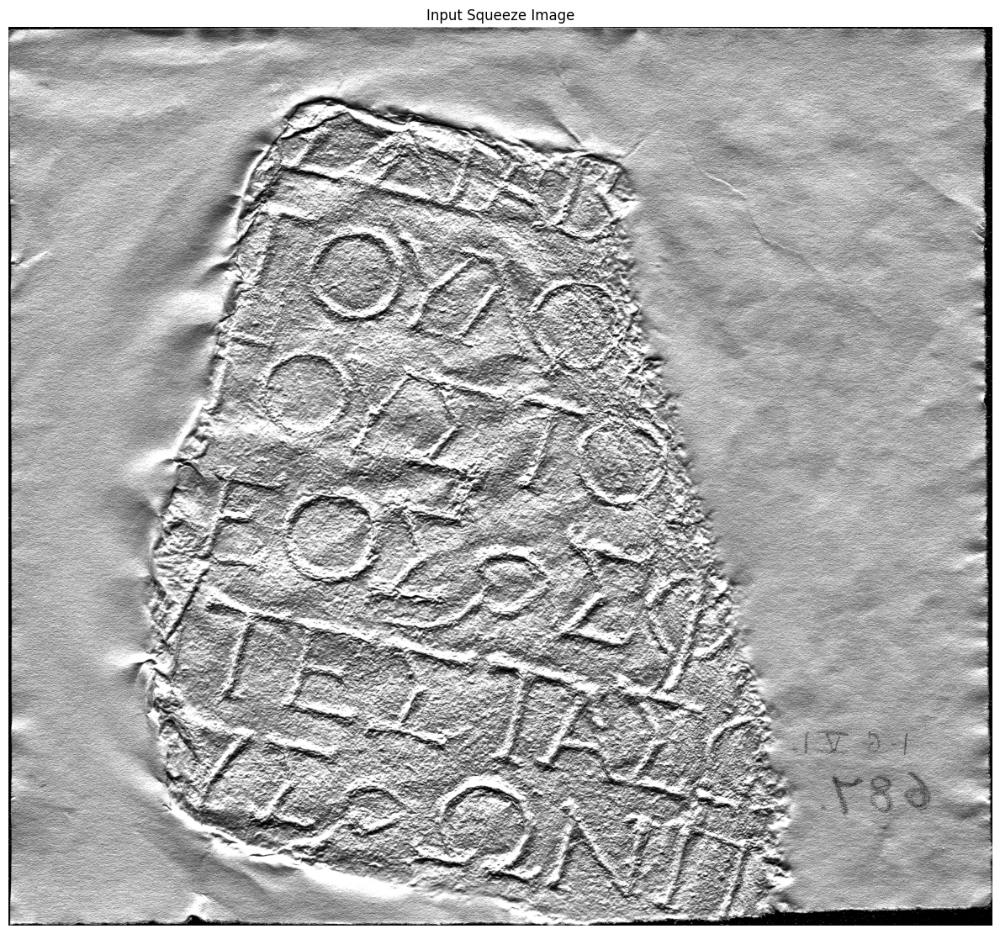

In [14]:
img = cv2.imread(IMG1_PATH)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12,12))
plt.imshow(img_rgb)
plt.axis("off")
plt.title("Input Squeeze Image")

plt.tight_layout()
plt.savefig(
    "pipeline_step1_input.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

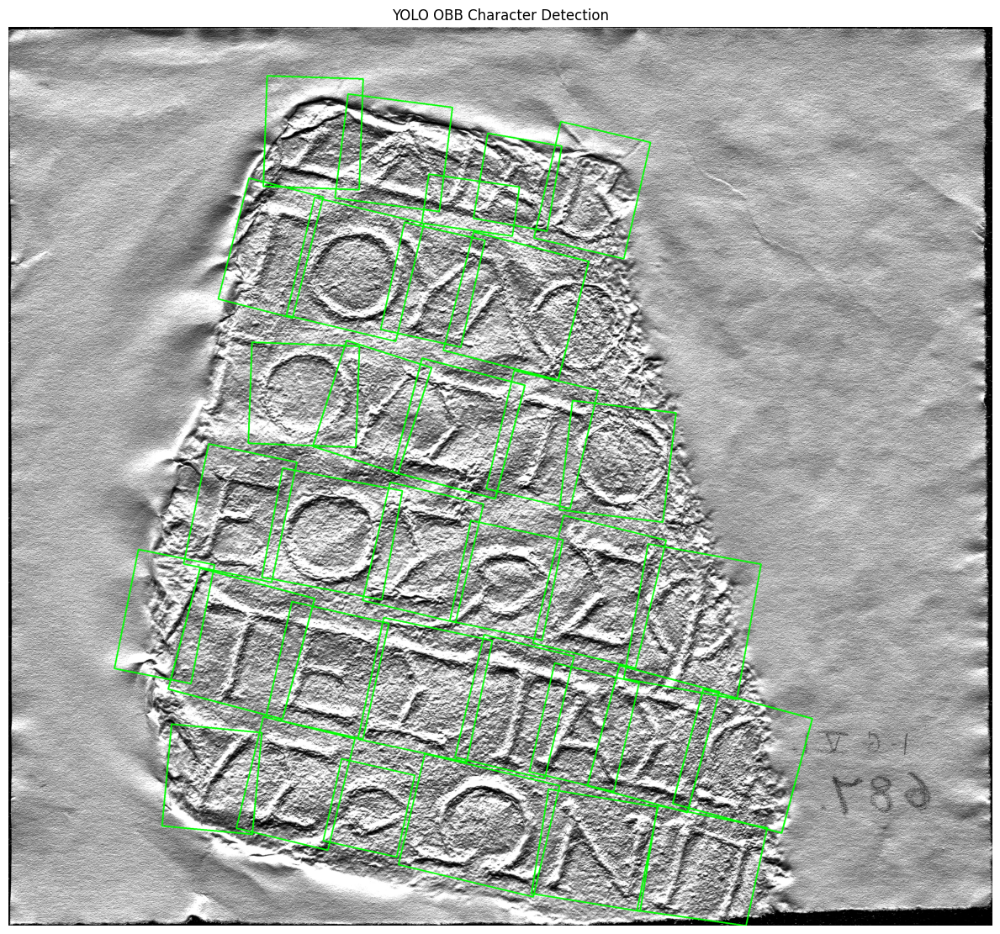

In [15]:
img = cv2.imread(IMG1_PATH)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

img_obb = img_rgb.copy()

for pred in boxes:

    poly = np.array(
        pred.mask.segmentation[0],
        dtype=np.float32
    ).reshape(-1, 2)

    poly = poly.astype(np.int32)

    cv2.polylines(
        img_obb,
        [poly],
        isClosed=True,
        color=(0,255,0),
        thickness=4
    )

plt.figure(figsize=(12,12))
plt.imshow(img_obb)
plt.axis("off")
plt.title("YOLO OBB Character Detection")

plt.tight_layout()
plt.savefig(
    "pipeline_step2_detection.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [16]:
sample_indices = np.linspace(
    0,
    len(boxes)-1,
    5,
    dtype=int
)

sample_boxes = [boxes[i] for i in sample_indices]

In [17]:
crops = []

for pred in sample_boxes:

    x1,y1,x2,y2 = map(
        int,
        pred.bbox.to_xyxy()
    )

    crop = img_rgb[y1:y2, x1:x2]

    crops.append(crop)

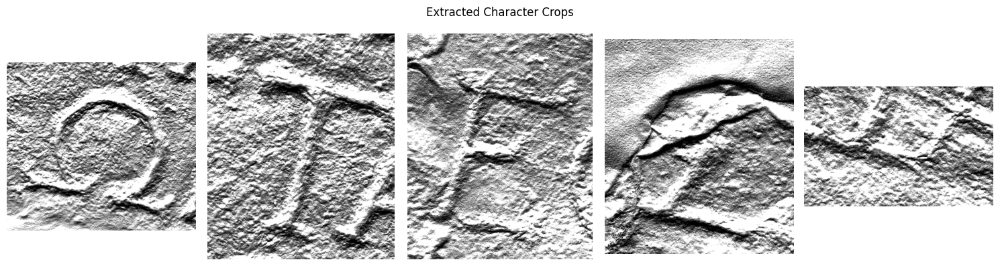

In [18]:
fig, axes = plt.subplots(
    1,
    len(crops),
    figsize=(15,4)
)

for ax, crop in zip(axes, crops):

    ax.imshow(crop)
    ax.axis("off")

plt.suptitle("Extracted Character Crops")

plt.tight_layout()

plt.savefig(
    "pipeline_step3_crops.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [19]:
classification_results = []

for crop in crops:

    tensor = cls_transforms(
        Image.fromarray(crop)
    ).unsqueeze(0).to(DEVICE)

    with torch.no_grad():

        logits = classifier(tensor)

        probs = F.softmax(
            logits,
            dim=1
        )

        conf, idx = torch.max(
            probs,
            1
        )

    classification_results.append({
        "label": CLASS_NAMES[idx.item()],
        "confidence": conf.item(),
        "probs": probs.cpu().numpy()[0]
    })

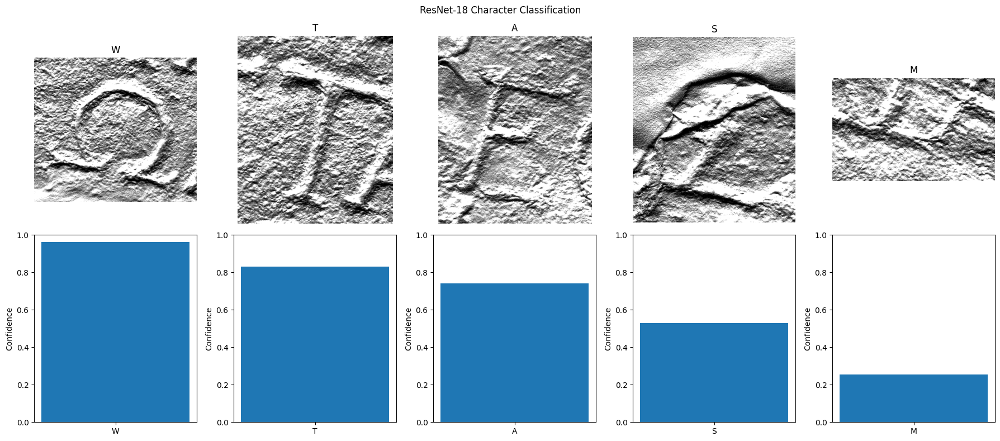

In [20]:
fig, axes = plt.subplots(
    2,
    len(crops),
    figsize=(18,8)
)

for i, (crop, result) in enumerate(
    zip(crops, classification_results)
):

    axes[0,i].imshow(crop)
    axes[0,i].axis("off")

    axes[0,i].set_title(
        result["label"]
    )

    axes[1,i].bar(
        [result["label"]],
        [result["confidence"]]
    )

    axes[1,i].set_ylim(0,1)

    axes[1,i].set_ylabel("Confidence")

plt.suptitle("ResNet-18 Character Classification")

plt.tight_layout()

plt.savefig(
    "pipeline_step4_classification.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

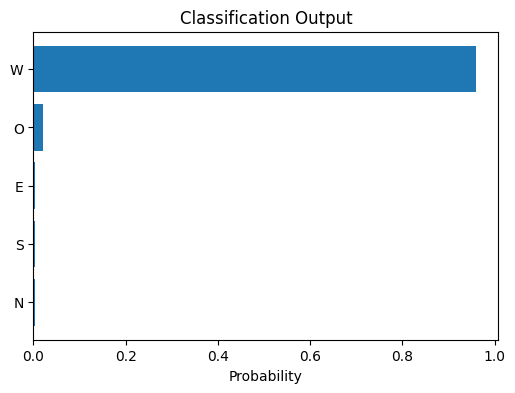

In [21]:
crop = crops[0]

tensor = cls_transforms(
    Image.fromarray(crop)
).unsqueeze(0).to(DEVICE)

with torch.no_grad():

    logits = classifier(tensor)

    probs = F.softmax(
        logits,
        dim=1
    )[0]

top_probs, top_ids = torch.topk(
    probs,
    5
)

labels = [
    CLASS_NAMES[i]
    for i in top_ids.cpu().numpy()
]

values = top_probs.cpu().numpy()

plt.figure(figsize=(6,4))

plt.barh(labels[::-1], values[::-1])

plt.xlabel("Probability")
plt.title("Classification Output")

plt.show()

In [22]:
results = []

for pred in boxes:

    x1,y1,x2,y2 = map(
        int,
        pred.bbox.to_xyxy()
    )

    crop = img_rgb[y1:y2, x1:x2]

    if crop.size == 0:
        continue

    tensor = cls_transforms(
        Image.fromarray(crop)
    ).unsqueeze(0).to(DEVICE)

    with torch.no_grad():

        probs = F.softmax(
            classifier(tensor),
            dim=1
        )

        conf, idx = torch.max(
            probs,
            1
        )

    results.append({
        'x1': x1,
        'y1': y1,
        'x2': x2,
        'y2': y2,
        'label': CLASS_NAMES[idx.item()],
        'conf': conf.item()
    })


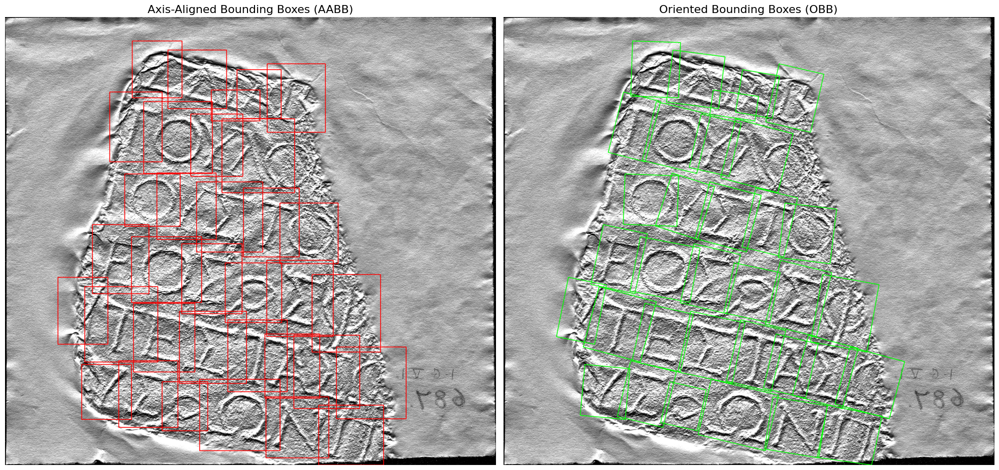

In [26]:
img = cv2.imread(IMG1_PATH)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

img_aabb = img_rgb.copy()
img_obb = img_rgb.copy()

for pred in boxes:

    # -----------------------
    # Axis-aligned box
    # -----------------------

    x1, y1, x2, y2 = map(
        int,
        pred.bbox.to_xyxy()
    )

    cv2.rectangle(
        img_aabb,
        (x1, y1),
        (x2, y2),
        (255, 0, 0),
        3
    )

    # -----------------------
    # OBB polygon
    # -----------------------

    poly = np.array(
        pred.mask.segmentation[0],
        dtype=np.float32
    ).reshape(-1, 2)

    poly = poly.astype(np.int32)

    cv2.polylines(
        img_obb,
        [poly],
        isClosed=True,
        color=(0, 255, 0),
        thickness=3
    )

fig, axes = plt.subplots(
    1,
    2,
    figsize=(20, 10)
)

axes[0].imshow(img_aabb)
axes[0].set_title(
    "Axis-Aligned Bounding Boxes (AABB)",
    fontsize=16
)
axes[0].axis("off")

axes[1].imshow(img_obb)
axes[1].set_title(
    "Oriented Bounding Boxes (OBB)",
    fontsize=16
)
axes[1].axis("off")

plt.tight_layout()

plt.savefig(
    "obb_vs_aabb.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [1]:
print("now for the new pathway 2")

now for the new pathway 2


In [2]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from sahi import AutoDetectionModel
from sahi.predict import get_sliced_prediction

In [3]:
IMG_PATH = "../data/raw/test_fullsized_images/IAS_27288_Rotation1_300dpi.png"

YOLO_WEIGHTS = "../runs/obb/train3/weights/best.pt"

CRNN_WEIGHTS = "../models/crnn_greek_20260420_155707_best.pth"

VOCAB_FILE = "../data/processed/crnn_training_data/labels.txt"

DEVICE = "cuda:0" if torch.cuda.is_available() else "cpu"

print("Using:", DEVICE)

Using: cpu


In [4]:
class GreekCRNN(nn.Module):
    def __init__(self, img_channels=1, num_chars=35, hidden_size=256):
        super(GreekCRNN, self).__init__()

        self.cnn = nn.Sequential(
            nn.Conv2d(img_channels,64,3,padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2,2),

            nn.Conv2d(64,128,3,padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2,2),

            nn.Conv2d(128,256,3,padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),

            nn.MaxPool2d((2,1),(2,1)),

            nn.Conv2d(256,512,3,padding=1),
            nn.BatchNorm2d(512),
            nn.ReLU(inplace=True),

            nn.MaxPool2d((2,1),(2,1)),

            nn.Conv2d(512,512,2),
            nn.BatchNorm2d(512),
            nn.ReLU(inplace=True)
        )

        self.rnn = nn.LSTM(
            input_size=512,
            hidden_size=hidden_size,
            num_layers=2,
            bidirectional=True,
            batch_first=True
        )

        self.fc = nn.Linear(
            hidden_size*2,
            num_chars+1
        )

    def forward(self,x):

        x = self.cnn(x)

        x = x.squeeze(2)

        x = x.permute(0,2,1)

        x,_ = self.rnn(x)

        return self.fc(x)


In [5]:
def decode_predictions(outputs, idx2char):

    _, max_indices = torch.max(outputs, dim=2)

    max_indices = max_indices.cpu().numpy()

    decoded_strings = []

    for seq in max_indices:

        pred = ""

        prev = -1

        for idx in seq:

            if idx != 0 and idx != prev:
                pred += idx2char[idx]

            prev = idx

        decoded_strings.append(pred)

    return decoded_strings

In [6]:
def order_points(pts):

    rect = np.zeros((4,2), dtype="float32")

    s = pts.sum(axis=1)

    rect[0] = pts[np.argmin(s)]
    rect[2] = pts[np.argmax(s)]

    diff = np.diff(pts, axis=1)

    rect[1] = pts[np.argmin(diff)]
    rect[3] = pts[np.argmax(diff)]

    return rect


In [7]:
def build_vocab(labels_file):

    chars = set()

    with open(labels_file, "r", encoding="utf-8") as f:

        for line in f:

            parts = line.strip().split("\t")

            if len(parts) == 2:
                chars.update(list(parts[1]))

    chars = sorted(chars)

    idx2char = {
        i+1:c
        for i,c in enumerate(chars)
    }

    char2idx = {
        c:i+1
        for i,c in enumerate(chars)
    }

    return char2idx, idx2char, len(chars)

In [8]:
char2idx, idx2char, num_chars = build_vocab(
    VOCAB_FILE
)

detector = AutoDetectionModel.from_pretrained(
    model_type="yolov8",
    model_path=YOLO_WEIGHTS,
    confidence_threshold=0.25,
    device=DEVICE
)

crnn_model = GreekCRNN(
    num_chars=num_chars
).to(DEVICE)

crnn_model.load_state_dict(
    torch.load(
        CRNN_WEIGHTS,
        map_location=DEVICE
    )
)

crnn_model.eval()

print("Models loaded.")

Models loaded.


In [9]:
img = cv2.imread(IMG_PATH)

img_gray = cv2.cvtColor(
    img,
    cv2.COLOR_BGR2GRAY
)

result = get_sliced_prediction(
    IMG_PATH,
    detector,
    slice_height=640,
    slice_width=640,
    overlap_height_ratio=0.2,
    overlap_width_ratio=0.2,
    postprocess_type="NMS"
)

predictions = result.object_prediction_list

print("Detections:", len(predictions))

Performing prediction on 42 slices.


[W722 12:36:56.007508746 NNPACK.cpp:62] Could not initialize NNPACK! Reason: Unsupported hardware.


Detections: 34


In [12]:
boxes_data = []

for i,p in enumerate(predictions):

    pts = np.array(
        p.mask.segmentation[0],
        dtype=np.float32
    ).reshape(-1,2)

    cx,cy = np.mean(pts, axis=0)

    d1 = np.linalg.norm(pts[0]-pts[2])
    d2 = np.linalg.norm(pts[1]-pts[3])

    r = 0.5 * max(d1,d2)

    boxes_data.append({
        "id":i,
        "pts":pts,
        "cx":cx,
        "cy":cy,
        "r":r
    })



In [13]:
for i, box_i in enumerate(boxes_data):

    left_neighbors = []
    right_neighbors = []

    for j, box_j in enumerate(boxes_data):

        if i == j:
            continue

        if abs(box_j["cy"] - box_i["cy"]) <= box_j["r"]:

            if box_j["cx"] < box_i["cx"]:
                left_neighbors.append(box_j)

            elif box_j["cx"] > box_i["cx"]:
                right_neighbors.append(box_j)

    box_i["left"] = (
        max(left_neighbors, key=lambda b: b["cx"])["id"]
        if left_neighbors else None
    )

    box_i["right"] = (
        min(right_neighbors, key=lambda b: b["cx"])["id"]
        if right_neighbors else None
    )

In [14]:
unassociated = set(range(len(boxes_data)))

candidate_rows = []

while unassociated:

    seed_id = unassociated.pop()

    current_row = [seed_id]

    curr_id = seed_id

    while True:

        left_id = boxes_data[curr_id]["left"]

        if left_id is not None and left_id in unassociated:

            current_row.insert(0, left_id)

            unassociated.remove(left_id)

            curr_id = left_id

        else:
            break

    curr_id = seed_id

    while True:

        right_id = boxes_data[curr_id]["right"]

        if right_id is not None and right_id in unassociated:

            current_row.append(right_id)

            unassociated.remove(right_id)

            curr_id = right_id

        else:
            break

    candidate_rows.append(
        [boxes_data[i] for i in current_row]
    )

In [15]:
lines = []

for row in candidate_rows:

    row.sort(key=lambda b: b["cx"])

    lines.append(row)

lines.sort(
    key=lambda row:
    sum(b["cy"] for b in row) / len(row)
)

print("Detected lines:", len(lines))

Detected lines: 7


In [16]:
for i, line in enumerate(lines):
    print(
        f"Line {i+1}: {len(line)} characters"
    )

Line 1: 4 characters
Line 2: 1 characters
Line 3: 4 characters
Line 4: 5 characters
Line 5: 6 characters
Line 6: 8 characters
Line 7: 6 characters


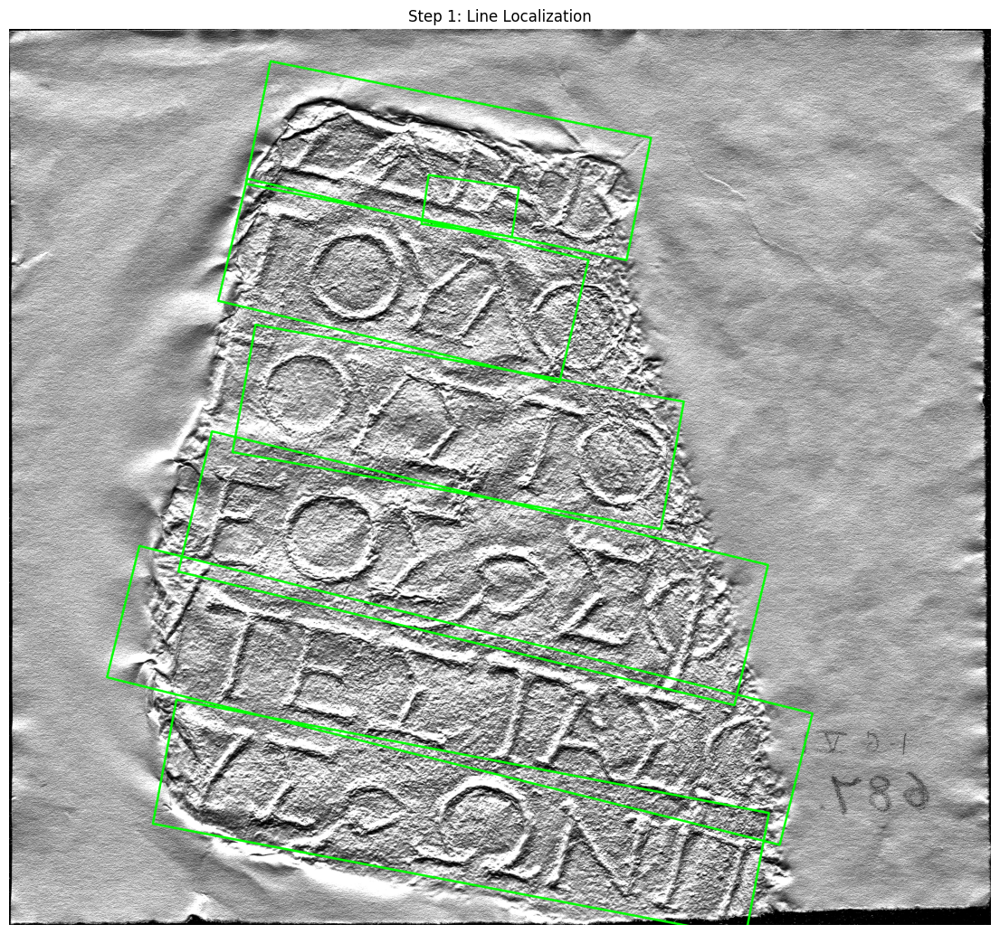

In [17]:
vis = img.copy()

for line in lines:

    all_pts = np.vstack(
        [b["pts"] for b in line]
    )

    rect = cv2.minAreaRect(
        all_pts.astype(np.float32)
    )

    box = cv2.boxPoints(rect)

    box = np.int32(box)

    cv2.polylines(
        vis,
        [box],
        True,
        (0,255,0),
        5
    )

plt.figure(figsize=(14,14))

plt.imshow(
    cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)
)

plt.axis("off")

plt.title("Step 1: Line Localization")

plt.show()

In [18]:
line = max(
    lines,
    key=len
)

print(
    "Characters:",
    len(line)
)

Characters: 8


In [19]:
all_pts = np.vstack(
    [b["pts"] for b in line]
)

rect = cv2.minAreaRect(
    all_pts.astype(np.float32)
)

(cx,cy),(w,h),angle = rect

if h > w:
    w,h = h,w
    angle -= 90

padded_w = w + h

padded_rect = (
    (cx,cy),
    (padded_w,h),
    angle
)

box = cv2.boxPoints(
    padded_rect
)

src_pts = order_points(box)

target_h = 32

target_w = int(
    padded_w * target_h / max(h,1)
)

dst_pts = np.array([
    [0,0],
    [target_w-1,0],
    [target_w-1,target_h-1],
    [0,target_h-1]
], dtype=np.float32)

M = cv2.getPerspectiveTransform(
    src_pts,
    dst_pts
)

deskewed = cv2.warpPerspective(
    img_gray,
    M,
    (target_w,target_h),
    borderValue=0
)

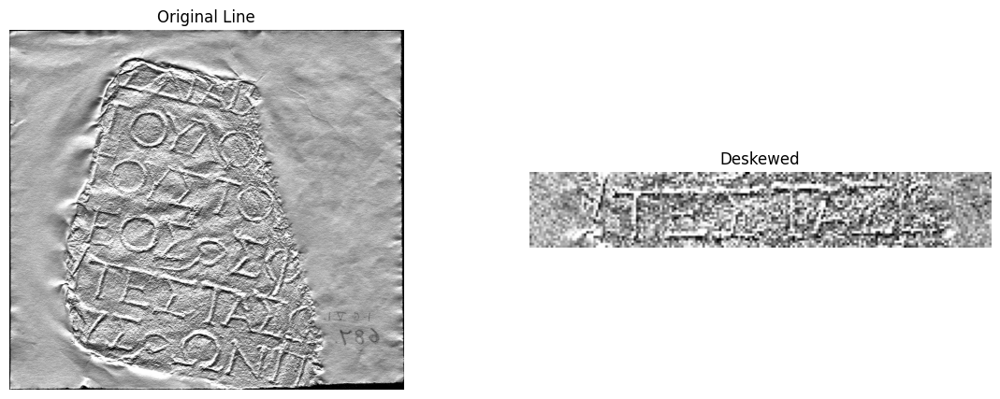

In [20]:
fig,ax = plt.subplots(
    1,2,
    figsize=(14,5)
)

ax[0].imshow(
    cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
)
ax[0].set_title("Original Line")
ax[0].axis("off")

ax[1].imshow(
    deskewed,
    cmap="gray"
)
ax[1].set_title("Deskewed")
ax[1].axis("off")

plt.show()

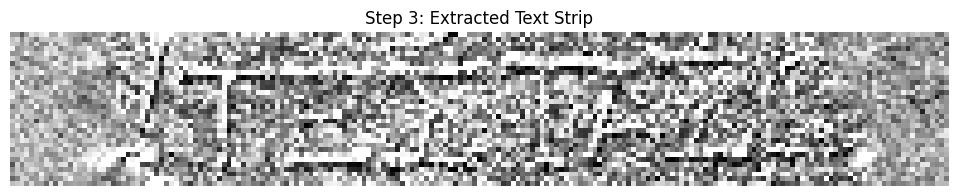

In [21]:
plt.figure(figsize=(16,2))

plt.imshow(
    deskewed,
    cmap="gray"
)

plt.axis("off")

plt.title(
    "Step 3: Extracted Text Strip"
)

plt.show()

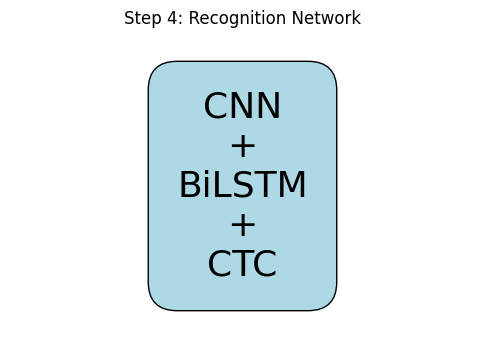

In [22]:
fig,ax = plt.subplots(
    figsize=(6,4)
)

ax.axis("off")

ax.text(
    0.5,
    0.5,
    "CNN\n+\nBiLSTM\n+\nCTC",
    fontsize=26,
    ha="center",
    va="center",
    bbox=dict(
        facecolor="lightblue",
        edgecolor="black",
        boxstyle="round,pad=0.8"
    )
)

plt.title("Step 4: Recognition Network")

plt.show()

In [23]:
input_tensor = (
    torch.FloatTensor(
        (deskewed / 127.5) - 1.0
    )
    .unsqueeze(0)
    .unsqueeze(0)
    .to(DEVICE)
)

with torch.no_grad():

    outputs = crnn_model(
        input_tensor
    )

pred_text = decode_predictions(
    outputs,
    idx2char
)[0]

print(pred_text)

TESTAS*


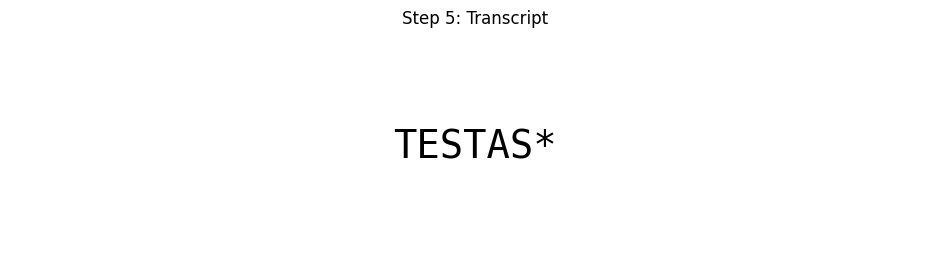

In [24]:
fig,ax = plt.subplots(
    figsize=(12,3)
)

ax.axis("off")

ax.text(
    0.5,
    0.5,
    pred_text,
    fontsize=28,
    family="monospace",
    ha="center",
    va="center"
)

ax.set_title(
    "Step 5: Transcript"
)

plt.show()